**Student Name:** Noah Pham

**BlazerID:** tpham6

# **Assignment 2 - Training and Investigating a Simple Language Model**

## Part 1: Prepare the Training and Validation Data


In [1]:
import torch
import tiktoken

torch.manual_seed(123)
tokenizer = tiktoken.get_encoding("gpt2")


class GPT_Dataset(torch.utils.data.Dataset):
    def __init__(self, text, tokenizer, max_length=8, stride=8):
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.stride = stride

        # Tokenize the text
        self.tokens = tokenizer.encode(text)

        # Create input and target sequences
        self.input_sequences = []
        self.target_sequences = []

        for i in range(0, len(self.tokens) - max_length, stride):
            input_seq = self.tokens[i : i + max_length]
            target_seq = self.tokens[i + 1 : i + max_length + 1]

            self.input_sequences.append(input_seq)
            self.target_sequences.append(target_seq)

    def __len__(self):
        return len(self.input_sequences)

    def __getitem__(self, idx):
        return torch.tensor(self.input_sequences[idx]), torch.tensor(
            self.target_sequences[idx]
        )

In [2]:
with open("llm_training_corpus.txt") as file:
    text = file.read()

# Split the text by character position
train_size = int(0.9 * len(text))
validation_size = len(text) - train_size

train_data = text[:train_size]
validation_data = text[train_size:]

# Create DataLoader objects
train_ds = GPT_Dataset(train_data, tokenizer, max_length=64, stride=64)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=2, shuffle=True)

validation_ds = GPT_Dataset(validation_data, tokenizer, max_length=64, stride=64)
validation_loader = torch.utils.data.DataLoader(
    validation_ds, batch_size=2, shuffle=False, drop_last=False
)

In [3]:
print(
    'The title or source of text: "Title: Foundations of Statistical Language Modeling and Natural Language Processing"'
)
print("\nThe number of characters:")
print("- In complete text:", len(text))
print("- In training data:", len(train_data))
print("- In validation data:", len(validation_data))
print("\nThe number of batches:")
print("- In training loader:", len(train_loader))
print("- In validation loader:", len(validation_loader))
print(
    "\nThe device used for training:",
    torch.device("cuda" if torch.cuda.is_available() else "cpu"),
)

The title or source of text: "Title: Foundations of Statistical Language Modeling and Natural Language Processing"

The number of characters:
- In complete text: 40532
- In training data: 36478
- In validation data: 4054

The number of batches:
- In training loader: 61
- In validation loader: 6

The device used for training: cpu


### Questions

#### 1.2 Why is the data separated into training and validation sets?

The data is divided into training and validation sets to evaluate how well the language model generalizes to unseen text. The training set is used to learn model parameters, while the validation set measures performance during development and helps identify overfitting.

#### 1.3 Why should validation data be evaluated without updating the model parameters?

Validation data should be evaluated without updating model parameters to provide an unbiased measure of generalization. Updating the parameters on validation data would expose the model to those examples, potentially causing overfitting and making the validation loss unreliable.


## Part 2: Implement and Verify the Model


In [4]:
class DummyModel(torch.nn.Module):
    def __init__(self, vocab_size=50257, embedding_dim=64):
        super().__init__()
        self.embedding = torch.nn.Embedding(vocab_size, embedding_dim)
        self.output = torch.nn.Linear(embedding_dim, vocab_size)

    def forward(self, x):
        x = self.embedding(x)
        return self.output(x)

In [5]:
model = DummyModel()
for input_batch, target_batch in train_loader:
    output = model(input_batch)
    print("The shape of input tensors:", input_batch.shape)
    print("The shape of logits tensors:", output.shape)
    print("The shape of target tensors:", target_batch.shape)
    break

The shape of input tensors: torch.Size([2, 64])
The shape of logits tensors: torch.Size([2, 64, 50257])
The shape of target tensors: torch.Size([2, 64])


### Questions

#### 2.1 What is the shape of the logit tensor, and what does each dimension represent?

The logit tensor has shape **[2, 64, 50257]**. The first dimension is the batch size, the second is the sequence length (64 tokens), and the third contains a logit score for each token in the vocabulary of 50257 tokens.

#### 2.2 Why must the logits and targets be flattened before cross-entropy loss is calculated?

Flattening converts logits from **[batch size, sequence length, vocabulary size]** to **[batch size × sequence length, vocabulary size]**, and targets from **[batch size, sequence length]** to **[batch size × sequence length]**. This allows cross-entropy loss to compare each token’s predicted vocabulary distribution with its corresponding target token.

#### 2.3 How many next-token predictions are evaluated in one batch? Show how you calculated the value.

There are **128 next-token predictions** in one batch:

**2 examples × 64 tokens per sequence = 128 predictions.**

Each prediction produces a probability distribution over the vocabulary.

## Part 3: Investigate Learning Rate


In [6]:
def train_model(
    model, train_loader, validation_loader, num_epochs=20, learning_rate=0.0003
):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    criterion = torch.nn.CrossEntropyLoss()

    val_losses = []
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        for input_batch, target_batch in train_loader:
            input_batch, target_batch = input_batch.to(device), target_batch.to(device)

            optimizer.zero_grad()
            output = model(input_batch)
            loss = criterion(output.view(-1, output.size(-1)), target_batch.view(-1))
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_training_loss = total_loss / len(train_loader)
        print(
            f"Epoch [{epoch + 1}/{num_epochs}], Training Loss: {avg_training_loss:.4f}"
        )

        # Validation
        model.eval()
        total_val_loss = 0
        with torch.no_grad():
            for input_batch, target_batch in validation_loader:
                input_batch, target_batch = (
                    input_batch.to(device),
                    target_batch.to(device),
                )
                output = model(input_batch)
                val_loss = criterion(
                    output.view(-1, output.size(-1)), target_batch.view(-1)
                )
                total_val_loss += val_loss.item()

        avg_validation_loss = total_val_loss / len(validation_loader)
        print(
            f"Epoch [{epoch + 1}/{num_epochs}], Validation Loss: {avg_validation_loss:.4f}"
        )
        val_losses.append(avg_validation_loss)

    return val_losses

In [7]:
val_losses_A = train_model(model, train_loader, validation_loader, learning_rate=0.0001)

Epoch [1/20], Training Loss: 10.9385
Epoch [1/20], Validation Loss: 10.8759


Epoch [2/20], Training Loss: 10.7873
Epoch [2/20], Validation Loss: 10.7525


Epoch [3/20], Training Loss: 10.6348
Epoch [3/20], Validation Loss: 10.6182


Epoch [4/20], Training Loss: 10.4824
Epoch [4/20], Validation Loss: 10.4918


Epoch [5/20], Training Loss: 10.3287
Epoch [5/20], Validation Loss: 10.3610


...

Epoch [16/20], Training Loss: 8.5766
Epoch [16/20], Validation Loss: 8.8639


Epoch [17/20], Training Loss: 8.4069
Epoch [17/20], Validation Loss: 8.7080


Epoch [18/20], Training Loss: 8.2345
Epoch [18/20], Validation Loss: 8.5686


Epoch [19/20], Training Loss: 8.0598
Epoch [19/20], Validation Loss: 8.4158


Epoch [20/20], Training Loss: 7.8837
Epoch [20/20], Validation Loss: 8.2630


In [8]:
val_losses_B = train_model(model, train_loader, validation_loader, learning_rate=0.0003)

Epoch [1/20], Training Loss: 7.5569
Epoch [1/20], Validation Loss: 7.8436


Epoch [2/20], Training Loss: 7.0386
Epoch [2/20], Validation Loss: 7.4316


Epoch [3/20], Training Loss: 6.5193
Epoch [3/20], Validation Loss: 6.9770


Epoch [4/20], Training Loss: 6.0031
Epoch [4/20], Validation Loss: 6.5701


Epoch [5/20], Training Loss: 5.5015
Epoch [5/20], Validation Loss: 6.1687


...

Epoch [16/20], Training Loss: 1.9460
Epoch [16/20], Validation Loss: 2.8816


Epoch [17/20], Training Loss: 1.8019
Epoch [17/20], Validation Loss: 2.6902


Epoch [18/20], Training Loss: 1.6799
Epoch [18/20], Validation Loss: 2.5454


Epoch [19/20], Training Loss: 1.5712
Epoch [19/20], Validation Loss: 2.3867


Epoch [20/20], Training Loss: 1.4807
Epoch [20/20], Validation Loss: 2.2364


In [9]:
val_losses_C = train_model(model, train_loader, validation_loader, learning_rate=0.001)

Epoch [1/20], Training Loss: 1.3203
Epoch [1/20], Validation Loss: 1.8396


Epoch [2/20], Training Loss: 1.1143
Epoch [2/20], Validation Loss: 1.5481


Epoch [3/20], Training Loss: 1.0162
Epoch [3/20], Validation Loss: 1.3721


Epoch [4/20], Training Loss: 0.9494
Epoch [4/20], Validation Loss: 1.2398


Epoch [5/20], Training Loss: 0.9116
Epoch [5/20], Validation Loss: 1.1535


...

Epoch [16/20], Training Loss: 0.8242
Epoch [16/20], Validation Loss: 1.0225


Epoch [17/20], Training Loss: 0.8187
Epoch [17/20], Validation Loss: 0.9999


Epoch [18/20], Training Loss: 0.8165
Epoch [18/20], Validation Loss: 1.0212


Epoch [19/20], Training Loss: 0.8171
Epoch [19/20], Validation Loss: 1.0390


Epoch [20/20], Training Loss: 0.8137
Epoch [20/20], Validation Loss: 0.9812


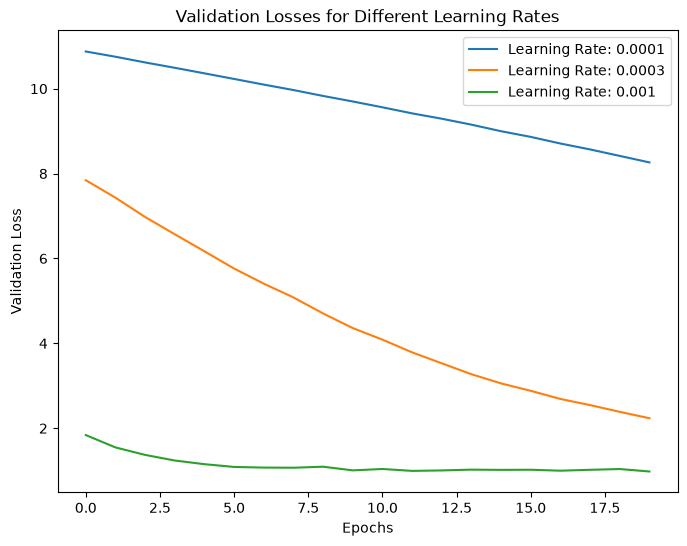

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.plot(val_losses_A, label="Learning Rate: 0.0001")
plt.plot(val_losses_B, label="Learning Rate: 0.0003")
plt.plot(val_losses_C, label="Learning Rate: 0.001")
plt.title("Validation Losses for Different Learning Rates")
plt.xlabel("Epochs")
plt.ylabel("Validation Loss")
plt.legend()
plt.show()

| Learning Rate | Epoch 1 Train Loss | Final Train Loss | Final Validation Loss |
| ------------: | -----------------: | ---------------: | --------------------: |
|        0.0001 |            10.9385 |           7.8837 |                8.2630 |
|        0.0003 |             7.5569 |           1.4807 |                2.2364 |
|        0.0010 |             1.3203 |           0.8137 |                0.9812 |

### Questions

#### 3.1 Which learning rate reduced training loss most quickly?

The learning rate **0.001** reduced training loss most quickly, reaching **1.3203 after the first epoch** and **0.8137** by epoch 20. Note that all three runs update the same `model` object in sequence, so each run resumes from the previous one's weights; the epoch 1 losses of 7.5569 and 1.3203 are inherited starting points rather than fresh ones.

#### 3.2 Which learning rate produced the lowest final validation loss?

The learning rate **0.001** produced the lowest final validation loss, at **0.9812**.

#### 3.3 Did the largest learning rate necessarily produce the best result? Explain using your evidence.

In this experiment the largest learning rate did give the best result: the lowest final training loss (**0.8137**) and the lowest final validation loss (**0.9812**). This is not guaranteed in general, and even here the 0.001 run was the least stable, with validation loss moving 0.9953 → 1.0390 → 0.9812 over the last epochs while training loss fell monotonically. A larger rate still would risk overshooting and diverging.

#### 3.4 What does this experiment show about the effect of learning rate on optimization and generalization?

Learning rate set how much of the loss the same 20-epoch budget could remove. At **0.0001** validation loss was still **8.2630** after 20 epochs, at **0.0003** it reached **2.2364**, and at **0.001** it reached **0.9812**. Faster optimization also translated into better generalization here, since the model was still underfitting rather than overfitting. The slight epoch-to-epoch bouncing at 0.001 shows the trade-off: larger steps converge faster but make each update noisier.

## Part 4: Investigate Model Capacity


In [11]:
model_A = DummyModel(vocab_size=50257, embedding_dim=32)
print(
    "Number of parameters in model_A:",
    sum(p.numel() for p in model_A.parameters() if p.requires_grad),
)

val_losses_A = train_model(
    model_A, train_loader, validation_loader, learning_rate=0.001
)

Number of parameters in model_A: 3266705


Epoch [1/20], Training Loss: 10.5589
Epoch [1/20], Validation Loss: 10.2528


Epoch [2/20], Training Loss: 9.6820
Epoch [2/20], Validation Loss: 9.5088


Epoch [3/20], Training Loss: 8.7385
Epoch [3/20], Validation Loss: 8.6341


Epoch [4/20], Training Loss: 7.6733
Epoch [4/20], Validation Loss: 7.6639


...

Epoch [16/20], Training Loss: 1.1555
Epoch [16/20], Validation Loss: 1.7126


Epoch [17/20], Training Loss: 1.0907
Epoch [17/20], Validation Loss: 1.5854


Epoch [18/20], Training Loss: 1.0455
Epoch [18/20], Validation Loss: 1.4772


Epoch [19/20], Training Loss: 1.0072
Epoch [19/20], Validation Loss: 1.3625


Epoch [20/20], Training Loss: 0.9778
Epoch [20/20], Validation Loss: 1.2832


In [12]:
model_B = DummyModel(vocab_size=50257, embedding_dim=64)
print(
    "Number of parameters in model_B:",
    sum(p.numel() for p in model_B.parameters() if p.requires_grad),
)

val_losses_B = train_model(
    model_B, train_loader, validation_loader, learning_rate=0.001
)

Number of parameters in model_B: 6483153


Epoch [1/20], Training Loss: 10.3009
Epoch [1/20], Validation Loss: 9.7510


Epoch [2/20], Training Loss: 8.6979
Epoch [2/20], Validation Loss: 8.3532


Epoch [3/20], Training Loss: 6.9542
Epoch [3/20], Validation Loss: 6.9011


Epoch [4/20], Training Loss: 5.1928
Epoch [4/20], Validation Loss: 5.5960


...

Epoch [16/20], Training Loss: 0.8697
Epoch [16/20], Validation Loss: 1.0038


Epoch [17/20], Training Loss: 0.8582
Epoch [17/20], Validation Loss: 1.0522


Epoch [18/20], Training Loss: 0.8537
Epoch [18/20], Validation Loss: 1.0584


Epoch [19/20], Training Loss: 0.8451
Epoch [19/20], Validation Loss: 1.0780


Epoch [20/20], Training Loss: 0.8402
Epoch [20/20], Validation Loss: 1.0323


In [13]:
model_C = DummyModel(vocab_size=50257, embedding_dim=128)
print(
    "Number of parameters in model_C:",
    sum(p.numel() for p in model_C.parameters() if p.requires_grad),
)

val_losses_C = train_model(
    model_C, train_loader, validation_loader, learning_rate=0.001
)

Number of parameters in model_C: 12916049


Epoch [1/20], Training Loss: 9.6254
Epoch [1/20], Validation Loss: 8.7184


Epoch [2/20], Training Loss: 6.7063
Epoch [2/20], Validation Loss: 6.4143


Epoch [3/20], Training Loss: 4.0733
Epoch [3/20], Validation Loss: 4.2754


Epoch [4/20], Training Loss: 2.4019
Epoch [4/20], Validation Loss: 2.9065


...

Epoch [16/20], Training Loss: 0.8329
Epoch [16/20], Validation Loss: 1.0540


Epoch [17/20], Training Loss: 0.8247
Epoch [17/20], Validation Loss: 0.9895


Epoch [18/20], Training Loss: 0.8217
Epoch [18/20], Validation Loss: 1.0254


Epoch [19/20], Training Loss: 0.8235
Epoch [19/20], Validation Loss: 1.0029


Epoch [20/20], Training Loss: 0.8206
Epoch [20/20], Validation Loss: 1.0389


| Embedding Dimension | Trainable Parameters | Final Train Loss | Final Validation Loss |
| ------------------: | -------------------: | ---------------: | --------------------: |
|                  32 |            3,266,705 |           0.9778 |                1.2832 |
|                  64 |            6,483,153 |           0.8402 |                1.0323 |
|                 128 |           12,916,049 |           0.8206 |                1.0389 |

### Questions

#### 4.1 How does increasing the embedding dimension affect the number of parameters?

It increases them roughly proportionally, because both the embedding table and the output layer scale with the dimension. The count roughly doubles at each step: **3,266,705** at 32, **6,483,153** at 64, and **12,916,049** at 128.

#### 4.2 Did a larger embedding dimension always produce a lower training loss?

Yes. Final training loss fell at every step: **0.9778**, **0.8402**, and **0.8206** for dimensions 32, 64, and 128.

#### 4.3 Did a larger embedding dimension always produce a lower validation loss?

No. Validation loss improved from **1.2832** at 32 to **1.0323** at 64, but then rose slightly to **1.0389** at 128. The 128-dimensional model reached **0.9577** at epoch 10 and then fluctuated, so the extra capacity bought no reliable improvement over 64.

#### 4.4 Does a larger model necessarily generalize better? Explain using your results.

No. The 128-dimensional model had the **lowest training loss (0.8206)** yet a **higher final validation loss (1.0389)** than the 64-dimensional model (**1.0323**), which is exactly the pattern of extra capacity being spent on fitting the training text rather than generalizing. Going from 32 to 64 dimensions helped a great deal (1.2832 → 1.0323), but doubling again returned nothing. Capacity helps only while the model is underfitting.

## Part 5: Select a Model and Generate Text

In Part 4 the 64-dimensional model reached the lowest final validation loss (**1.0323**), while the 128-dimensional model reached the lowest final training loss (**0.8206**) and the lowest validation loss seen at any epoch (**0.9577** at epoch 10). The two are within the run-to-run variation of this setup, so `model_C` (128 dimensions, learning rate 0.001, final training loss **0.8206**, final validation loss **1.0389**) is used for generation.


In [14]:
temperature = 0.8
top_k = 50
top_p = 0.95
max_new_tokens = 50

prompt = "language"

In [15]:
def generate_text(model, prompt, max_new_tokens, temperature, top_k, top_p):
    device = next(model.parameters()).device
    model.eval()

    token_ids = tokenizer.encode(prompt)
    generated = torch.tensor([token_ids], dtype=torch.long, device=device)

    with torch.no_grad():
        for _ in range(max_new_tokens):
            context = generated[:, -64:]
            logits = model(context)[:, -1, :] / temperature

            if top_k is not None:
                threshold = torch.topk(logits, top_k).values[:, -1].unsqueeze(-1)
                logits[logits < threshold] = float("-inf")

            probabilities = torch.softmax(logits, dim=-1)

            sorted_probs, sorted_indices = torch.sort(probabilities, descending=True)
            cumulative_probs = torch.cumsum(sorted_probs, dim=-1)
            remove = cumulative_probs > top_p
            remove[:, 1:] = remove[:, :-1].clone()
            remove[:, 0] = False

            sorted_probs[remove] = 0
            probabilities = torch.zeros_like(probabilities).scatter(
                1, sorted_indices, sorted_probs
            )
            probabilities /= probabilities.sum(dim=-1, keepdim=True)

            next_token = torch.multinomial(probabilities, num_samples=1)
            generated = torch.cat((generated, next_token), dim=1)

    return tokenizer.decode(generated[0].tolist())


for i in range(3):
    print(f"Generation {i + 1}:")
    print(generate_text(model_C, prompt, max_new_tokens, temperature, top_k, top_p))
    print("-" * 80)

Generation 1:
language logits over subsequent tokens as the product from sinusoidal encodings to maximize compute efficiency), and architectural normalization techniques include weight decay, ..., ..., ..., or Unigram Language Modeling.
The core building block of adaptive
--------------------------------------------------------------------------------
Generation 2:


language Learning rate scheduling typically adheres to applying the probabilistic chain rule as the span of a linear warmup phase followed by cosine decay variants of tokens as the span of P(x_1, keys, x_k)) V) and
--------------------------------------------------------------------------------
Generation 3:
languageabilistic chain rule as Byte-attention matrices. Optimization is predominantly conducted using scaled dot-entropy loss over subsequent tokens as the model to T of conditional probabilities over vast corpora. Learning rate scheduling typically adheres to T of conditional
--------------------------------------------------------------------------------


### Questions

#### 5.1 Are the three generated passages identical? Why or why not?

No. The weights and the prompt are the same in all three calls, but the next token is drawn with `torch.multinomial` from the temperature/top-k/top-p filtered distribution. `torch.manual_seed(123)` at the top makes the notebook reproducible from run to run, but the three calls consume successive values from the same random stream, so each one follows a different path.

#### 5.2 Does the output reflect vocabulary or patterns from the training text? Give an example.

Yes. The generations reuse phrases from the corpus verbatim, for example "Learning rate scheduling typically adheres to", "the product of conditional probabilities over vast corpora", and "from sinusoidal encodings to rotary position embedd".

#### 5.3 Does decreasing loss guarantee meaningful generated text? Explain using your results.

No. With a validation loss of **1.0389** the output is only locally fluent and breaks down within a clause, as in "language logits over subsequent tokens as the product from sinusoidal encodings to maximize compute efficiency), and architectural normalization techniques include weight decay, ..., ..., ...". The low loss reflects accurate token-by-token prediction on a small, repetitive corpus, not coherent text.


In [16]:
print(generate_text(model_C, prompt, max_new_tokens, 0.5, top_k, top_p))

language scheduling typically adheres to T of tokens. Learning rate scheduling typically adheres to maximize compute efficiency), and values to a linear warmup phase followed by cosine decay or inverse square root decay.


The core building block of a linear warm


In [17]:
print(generate_text(model_C, prompt, max_new_tokens, 0.8, top_k, top_p))

language language models formulate the product of conditional probabilities over vast corpora. Positional encodings—ranging from sinusoidal encodings to rotary position embedd_T / sqrt(x) placed in modern massive scale architectures to information from


In [18]:
print(generate_text(model_C, prompt, max_new_tokens, 1.2, top_k, top_p))

language(x) placed in a sequence x_2, V) with SwiBi—infuse crucial token order signals into subspaces at different positions. Positional encodings (x_1, often leading to rotary position embedd


| Experiment | Temperature | Observations                                                                                                                                                                                                                                      |
| ---------: | ----------: | :------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
|          A |         0.5 | Most conservative. Repeats whole phrases verbatim ("Learning rate scheduling typically adheres to" appears twice, and "a linear warm" twice) and stays on the highest-probability continuations.                                                  |
|          B |         0.8 | Balanced. Produces the longest genuinely readable run ("language models formulate the product of conditional probabilities over vast corpora. Positional encodings—ranging from sinusoidal encodings to rotary position embedd") before breaking. |
|          C |         1.2 | Most varied and least coherent. Splices notation fragments ("(x) placed in a sequence x_2, V)") and invents forms not in the corpus, such as "SwiBi".                                                                                             |

### Questions

#### 6.1 What differences did you observe between temperatures 0.5 and 1.2?

At 0.5 the output was repetitive, re-entering the same memorized phrase twice within 50 tokens. At 1.2 there was almost no repetition, but the tokens came from a much wider range and produced broken notation and the non-word "SwiBi". Higher temperature bought variety at the cost of coherence.

#### 6.2 Which temperature produced the most predictable output?

**0.5.**

#### 6.3 Which temperature produced the most varied or unexpected output?

**1.2.**

#### 6.4 Why does temperature change the output even though the model parameters do not change?

Temperature divides the logits before the softmax. Below 1 it sharpens the distribution toward the highest-scoring token; above 1 it flattens it and raises the chance of sampling unlikely tokens. The parameters produce the same logits every time, and only the sampling distribution derived from them changes.

## Part 7: Investigate the Limitation of the Model


In [19]:
sequence_1 = "the cat sat on the"
sequence_2 = "the students walked to the"

generated_sequence_1 = generate_text(model_C, sequence_1, 5, temperature, top_k, top_p)
generated_sequence_2 = generate_text(model_C, sequence_2, 5, temperature, top_k, top_p)

print(f'First generated sequence: "{generated_sequence_1}"')
print(f'Second generated sequence: "{generated_sequence_2}"')

First generated sequence: "the cat sat on the model to applying the product"
Second generated sequence: "the students walked to the joint probability P(x"


### Questions

#### 7.1 When predicting the token after the final "the," what information is supplied to the linear layer?

Only the embedding vector of that single token. The forward pass is `self.output(self.embedding(x))`, so the linear layer receives the 128-dimensional embedding row for the token id of "the" and nothing else.

#### 7.2 Does the representation of the final "the" depend on the preceding words? Explain from the architecture.

No. `DummyModel` is an embedding lookup followed by a linear layer applied independently at every position, with no attention, recurrence, convolution, or positional embeddings. Nothing in the architecture lets information move from one position to another.

#### 7.3 Will the final "the" have a different representation in the two sequences above? Why or why not?

No, it is identical. "the" has the same token id in both sequences, so it indexes the same embedding row and produces exactly the same logits. The continuations differ ("the model to applying the product" versus "the joint probability P(x") only because of random sampling.

#### 7.4 What important information is the model unable to use when predicting the next token?

All preceding context: the identity and order of the earlier words, the syntax they establish, and the position of the current token in the sequence. "cat sat on" and "students walked to" have no effect whatsoever on the prediction.

#### 7.5 How can training loss decrease even though the model cannot use preceding context?

It can still learn a fixed successor distribution for each token id, that is, which tokens most often follow that token anywhere in the corpus. On a small and highly repetitive text this removes most of the entropy, which is why training loss fell from about **9.63** to **0.8206** with no context at all.

#### 7.6 What capability would a better language model need to distinguish between the two occurrences of "the"

A mechanism that mixes information across positions, namely self-attention together with positional encoding, so that each occurrence of "the" is represented as a function of the surrounding tokens rather than its token id alone.

## Part 8: Overall Analysis

#### 8.1 What did changing the learning rate teach you about training a language model?

The learning rate, not the epoch count, decided how far the same 20-epoch budget got. Validation loss after 20 epochs was **8.2630** at 0.0001, **2.2364** at 0.0003, and **0.9812** at 0.001. The fastest rate was also the noisiest, moving 0.9953 → 1.0390 → 0.9812 over the final epochs while training loss fell steadily.

#### 8.2 What did changing the embedding dimension teach you about model capacity?

Parameters roughly double at each step (**3,266,705**, **6,483,153**, **12,916,049**) because both the embedding table and the output layer scale with the dimension. More capacity always fit the training data better (**0.9778**, **0.8402**, **0.8206**), but generalization stopped improving: validation loss went **1.2832** → **1.0323** → **1.0389**. Capacity helps only while the model is underfitting.

#### 8.3 Why is validation loss more useful for model selection than training loss alone?

Training loss only measures data the model has already been updated on, so it keeps falling during memorization. In Part 4 the 128-dimensional model had the lowest training loss (**0.8206**) but not the lowest validation loss (**1.0389** against **1.0323**), so training loss alone would have picked the wrong model. Validation loss also exposed instability that the smooth training curve hid, swinging from **0.9577** at epoch 10 to **1.1346** at epoch 13.

#### 8.4 What relationship did you observe between loss and generated-text quality?

Reaching a validation loss near 1.0 was enough for correct technical vocabulary and locally correct phrasing, such as "the product of conditional probabilities over vast corpora". Further loss reduction bought no coherence: the same model still produced "language logits over subsequent tokens as the product from sinusoidal encodings to maximize compute efficiency". Because the model cannot use context, lower loss improves single-token statistics rather than sentence structure, so quality plateaus well before loss does.

#### 8.5 What is the most important limitation of DummyModel?

It has no way for one token to see another, since the embedding and linear layers act independently at each position. The prediction after "the" is therefore identical in "the cat sat on the" and "the students walked to the", leaving word order, syntax, and long-range meaning invisible. That context-free floor is why all three model sizes converged near a training loss of 0.82.

#### 8.6 Why does a language model need a mechanism that allows a token to incorporate information fromother tokens in the sequence?

The same token continues very differently depending on what came before it, and agreement, coreference, and topic tracking all require reading earlier tokens. Self-attention supplies this by building each position's representation as a weighted combination of the other positions, with positional encoding indicating where those tokens sit. Without it the loss floor is fixed by corpus successor statistics, exactly the **0.82** floor every model size hit regardless of capacity.
